# Assignment 09: Gradient Forest and Genomic Turnover

## BIO597 Spatial Analysis of Biodiversity

Repeat the [Lab09](../labs/Lab09-GradientForest.ipynb) workflow for a snake species other than *P. guttatus*. Use SNP genotypes and climate predictors to investigate where modeled genetic turnover occurs along environmental gradients. You may reuse code from the lab.

## Deliverable

Submit this completed notebook with sample maps, SNP diagnostics, predictor importance, turnover curves, an aggregate PCA map/biplot, a single-SNP map/biplot, and short written answers. Save your diagnostic tables, transformed sample coordinates, curves, figures, and a GeoTIFF with one named band per predictor. Use the lab's filtering and model settings; no parameter search, additional algorithm, or future-climate projection is required.


## Install pyGF

Because this notebook environment is a bit wonky you need to redo this install every time you run a new notebook process.

The `pyGF` package is only available in my github repo, so the installation will need to be
'by hand'.

* Open a new terminal and `cd ~` to go to your home directory
* You should already have cloned the pygf repo so you don't need to do this again (but if you need to the command is `git clone https://github.com/isaacovercast/pygf.git`)
* `pip install -e pygf` to install this package and all requirements
* Restart the kernel for this notebook w/ the 'circle arrow' button in the notebook toolbar
* Now you should be able to do the imports in the next cell

## 1. Import packages and set up paths

Run this notebook from `docs/assignments` using the same Python environment as Lab09, with `pygf` and its notebook dependencies installed. The imports and JupyterHub paths are provided below.

The assignment's genetic data are in **`/home/jovyan/shared/EasternSnakeGenetics`**. The climate layers use the same **`/home/jovyan/shared-readwrite/bioclim`** directory as Lab09. Keep all input paths in these two variables so later calls use the same files. Save your results in your own repository, not in a shared input directory.

For local work, the genetic files are in `../labs/EasternSnakes`; you must also point `bioclim_dir` to a local directory containing the 19 regional bioclim rasters. The Maine-only climate layers from earlier labs do not cover these samples.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pygf import GradientForest, read_coordinates, read_vcf, sample_environment

genetics_dir = Path("/home/jovyan/shared/EasternSnakeGenetics")
bioclim_dir = Path("/home/jovyan/shared-readwrite/bioclim")


## 2. Choose another snake species

Choose one of the three species with both a VCF and a headerless coordinate file. Use the **file stem** exactly as shown; do not choose the lab's `Pguttatus`.

| File stem | Species | Genetic files |
| --- | --- | --- |
| `Acontortrix` | *Agkistrodon contortrix* | `Acontortrix.vcf`, `Acontortrix_coords.txt` |
| `Lgetula` | *Lampropeltis getula* | `Lgetula.vcf`, `Lgetula_coords.txt` |
| `Sdekayi` | *Storeria dekayi* | `Sdekayi.vcf`, `Sdekayi_coords.txt` |

The `.txt` coordinate files contain sample ID, longitude, and latitude **without a header**, as expected by `read_coordinates()`. Use these files rather than the similarly named `.csv` tables.


In [6]:
target_species = "Lgetula"

species_names = {
    "Acontortrix": "Agkistrodon contortrix",
    "Lgetula": "Lampropeltis getula",
    "Sdekayi": "Storeria dekayi",
}
assert target_species in species_names, "/home/jovyan/shared/EasternSnakeGenetics/Lgetula.vcf"

species_name = species_names[target_species]
vcf_path = genetics_dir / f"{target_species}.vcf"
coords_path = genetics_dir / f"{target_species}_coords.txt"
assert vcf_path.is_file(), f"VCF not found: {vcf_path}"
assert coords_path.is_file(), f"Coordinates not found: {coords_path}"

output_dir = Path("Assignment09_outputs") / target_species
output_dir.mkdir(parents=True, exist_ok=True)
print(species_name)
print(vcf_path)
print(coords_path)


Lampropeltis getula
/home/jovyan/shared/EasternSnakeGenetics/Lgetula.vcf
/home/jovyan/shared/EasternSnakeGenetics/Lgetula_coords.txt


**Why this species?** Give one biological reason for your choice.

*Your answer:* Common kingsbnakes are fairly common snakes in the Southeastern and Southwestern US.

## 3. Read coordinates and filtered genotypes

Read `coords_path` into `sites` with `read_coordinates()`. Read `vcf_path` into `genotypes` with `read_vcf()`, passing `samples=sites` so genotype rows follow coordinate-file order. Keep the lab settings:

- `min_call_rate=0.8`
- `min_maf=0.05`
- `one_per_contig=True`
- `max_variants=256`
- `random_state=42`

Display the number of individuals and retained SNPs. Map the sample locations with a title naming your species. These points describe sampling, not the species' entire range.


<Axes: >

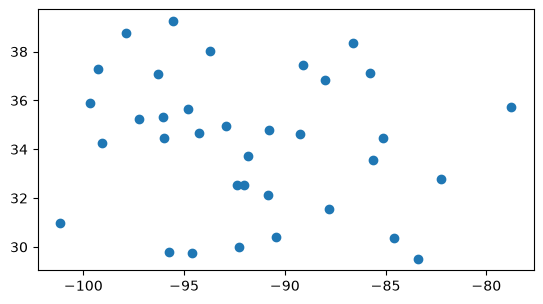

In [9]:
# Read coordinates as sites.
# Read the VCF as genotypes, using samples=sites and all five settings above.
# Use genotypes.dosage.to_pandas().shape to inspect individuals × SNPs.
# Print the dimensions and plot sites with a species title.

sites = read_coordinates("/home/jovyan/shared/EasternSnakeGenetics/Lgetula_coords.txt")
genotypes = read_vcf(
    "/home/jovyan/shared/EasternSnakeGenetics/Lgetula.vcf", 
    # opens a variant call format which stores DNA sequence variations across different individuals
    samples=sites,
    # filters the genetic dataset to keep only the individuals listed in sites variable
    min_call_rate=0.8,
    # removes low-quality genetic markers by requiring that at least 80% of the samples have valid, non-missing data for a 
    # given variant
    min_maf=0.05,
    # sets a minor allele frequency threshold of 5% which removes vey rare genetic variants that appear in fewer than 5% 
    # of the sampled chromosomes
    one_per_contig=True,
    # keeps only one genetic variant per contig (a continuous stretch of assembled DNA) which prevents closely linked variants 
    # from skewing downstreams populations
    max_variants=256,
    # randomly downsamples the remaining passing variants so the final dataset contains at most 256 markers
    random_state=42,
    # sets a fixed seed for the random number generator
)
sites.plot()
# calls a built-in plotting method on the sites object to generate a visual map showing where the snake sample were collected but no map


**Interpretation:**

1. What do dosage values 0, 1, and 2 represent? How does a missing call differ from a zero? 0 means the individual has 0 copies of alternate allele, 1 means the indiivudal has 1 copy of an alternative allele and 1 copy of the reference allele, and 2 means the individual has two copies of alternate allele. A 0 is a confident biological observation whereas a mising call means sequencing either failed or lacked enough read depth to determine the genotyope and must be excluded rather than treated as a 0.
2. What do call rate and minor allele frequency filter out? Why might the chosen SNP subset affect your conclusions? Call rate is the eprcentage of sampled snakes that have non-missing genotype data at a given SNP. Minor allele frequency is the proportion of the less common allele across the sampled population. The chosen SNP subset affects conclusions because max_variants=256 randomly downsamples the genome toa  small fraction of markers, different random subsets can capture or miss specific adaptive loci.
3. Why does taking one SNP per RAD contig reduce repeated local information without guaranteeing independent loci? It reduces local information because a RAW contig is a short, continous stretch fo DNA sequence and multiple SNPs located on the exact same contig are physically right nex tto each other on the chromosome so they are almost always inherited trogether as a single block through physical linking. Since RAD sequencing produces thousands fo short contigs scattered across the genome and different contigs can still sit relatively close together on the same chorosome does not guardent independent loci. 

## 4. Sample climate and align individuals

Extract all 19 climate variables at the sample locations. The provided code removes rows with missing climate and aligns all three inputs to the same IDs. Missing genotypes remain `NaN`; each SNP's forest uses its observed calls. Do not replace missing genotypes with zeros.

`sample_environment()` reprojects points to the raster CRS and samples raster values at those locations. It also remembers the source directory and sampling region for mapping.


In [11]:
bioclim_dir = "/home/jovyan/shared/bioclim"

n_before = len(sites)
X = sample_environment(bioclim_dir, sites, drop_missing=True)
y = genotypes.dosage.to_pandas().loc[X.index]
sites = sites.loc[X.index].copy()

assert sites.index.equals(X.index)
assert X.index.equals(y.index)
assert np.isfinite(X.to_numpy()).all()
assert X.shape[1] == 19, "Use the full regional bioclim stack."

print("Individuals before climate extraction:", n_before)
print("Individuals with complete climate:", len(X))
print("Climate predictors:", X.shape[1])
print("Filtered SNPs:", y.shape[1])
X.head()


Individuals before climate extraction: 35
Individuals with complete climate: 35
Climate predictors: 19
Filtered SNPs: 256


,bio1,bio2,bio3,bio4,bio5,bio6,bio7,bio8,bio9,bio10,bio11,bio12,bio13,bio14,bio15,bio16,bio17,bio18,bio19
sample,,,,,,,,,,,,,,,,,,,
KU289566,18.021166,12.363000,38.280281,762.018799,33.695999,1.400,32.295998,18.048000,26.525999,27.170666,8.384000,1349.0,142.0,77.0,18.694174,392.0,254.0,271.0,387.0
MVZ175927,15.514334,12.580000,37.791393,784.050110,31.972000,-1.316,33.288002,24.432001,10.992000,25.036667,5.627333,1153.0,117.0,76.0,14.071637,334.0,244.0,325.0,276.0
MVZ137799,17.981667,13.472667,42.624229,694.819580,33.571999,1.964,31.607998,26.351334,18.676001,26.351334,9.206000,1151.0,127.0,64.0,21.239332,355.0,208.0,355.0,301.0
OMNH12624,15.600833,12.677667,34.238052,881.593811,33.712002,-3.316,37.028000,20.011999,4.356000,26.182667,4.356000,938.0,137.0,35.0,38.403603,331.0,128.0,236.0,128.0
OMNH5006,16.283833,12.701667,35.083599,850.644043,33.875999,-2.328,36.203999,20.257334,5.423333,26.458000,5.423333,1104.0,145.0,53.0,30.947641,371.0,184.0,245.0,184.0


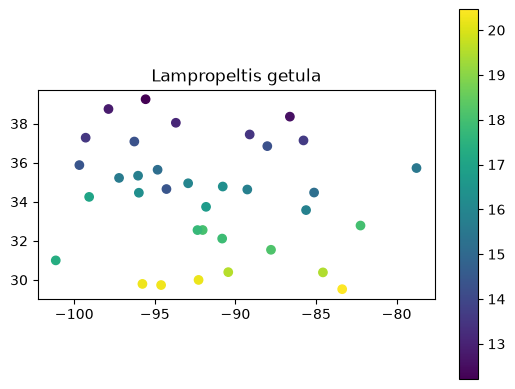

variant,RAD_31:10:G:C,RAD_161:65:C:T,RAD_260:91:A:T,RAD_353:8:A:G,RAD_675:58:C:T,RAD_695:7:A:G,RAD_907:26:G:A,RAD_991:17:T:C,RAD_1030:42:G:A,RAD_1064:68:A:C,...,RAD_25941:54:C:T,RAD_26005:40:G:A,RAD_26081:33:G:A,RAD_26228:112:C:T,RAD_26352:14:T:C,RAD_26354:32:A:C,RAD_26363:7:G:A,RAD_26374:51:G:A,RAD_26390:32:G:A,RAD_26564:2:T:C
sample,,,,,,,,,,,,,,,,,,,,,
KU289566,0.0,1.0,0.0,0.0,1.0,2.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,NaN,NaN,1.0,0.0,1.0
MVZ175927,2.0,0.0,0.0,0.0,0.0,2.0,2.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,2.0,0.0,0.0,1.0
MVZ137799,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,2.0,...,0.0,0.0,0.0,0.0,0.0,2.0,2.0,0.0,0.0,1.0
OMNH12624,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0
OMNH5006,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,1.0,1.0,NaN,0.0,2.0,1.0,0.0,2.0,2.0


In [13]:
# Map sites colored by X["bio1"] with a legend and species title.
# Inspect y.head() to confirm that SNPs are columns and individuals are rows.

ax = sites.plot(column=X["bio1"], legend=True)
ax.set_title(species_name)
plt.show()

y.head()

**Interpretation:** Were any individuals removed for missing climate? Why must `sites`, `X`, and `y` retain the same IDs and row order? Explain why these responses are individual genotypes rather than population allele frequencies.

*Your answer:*

## 5. Fit SNP-specific forests

Create `gf = GradientForest(...)` using `n_estimators=100`, `max_level=2`, `random_state=42`, and `keep_response_curves=True`, then fit it with `X` and `y`.

These settings match the lab. `max_level=2` controls approximate conditional permutations for correlated predictors; it does not limit tree depth. Retaining response curves lets us inspect one SNP later.


In [14]:
# Create gf with the four settings above and fit it to X and y.
# Display gf.response_scores_ sorted by descending oob_r2.

gf = GradientForest(
    n_estimators=100, max_level=2, random_state=42, keep_response_curves=True,
    # n_estimators=100 builds a random forest of 100 decision trees for every individual genetic markers in y (256 forests in total here)
    # max_level=2 controls how predictor importance is calculated when climate variables are correlated with each other, setting this to 2 
    # uses a conditional permutation grid up to 2 tree levels deep, preventing correlated climate variables from artificially inflating 
    # each other's importance scores
    # keep_response_curves=True tells the model to save teh individual turnover curves for each SNP rather than discarding them after 
    # averaging which allows us to inspect or plot single SNPs later
).fit(X, y)
# trains the forets using environmental data (x) to predict genetic data (y)
gf.response_scores_.sort_values("oob_r2", ascending=False).head()
# gf. stores the trained model and all its calculated results inside the gf variable
# gf.response_scores_ accesses a summary table generated by the model containing performance metrics for every SNP, including sample 
# coverage and whether teh SNP was kept or skipped
# .sort_values("oob_r2", ascending=False) sorts the summary table from highest to lowest based on oob_r2 (out of bag r2) which measures
# how accurately the climate variables predict a SNP's genotype on samples left out during tree training, higher positive values means a stronger
# link to the enivornment

# this code trains a gradient forest machine learning model on climate (x) and gnetic (y) data and then displays the top 5 genetic markers 
# (SNPs) that are best predicted by the environment


,n_observed,oob_r2,oob_coverage,retained,reason
response,,,,,
RAD_13936:1:G:A,31,0.494156,1.0,True,retained
RAD_4799:24:T:G,28,0.478255,1.0,True,retained
RAD_161:65:C:T,29,0.388318,1.0,True,retained
RAD_695:7:A:G,31,0.349667,1.0,True,retained
RAD_13270:102:C:T,28,0.347786,1.0,True,retained


## 6. Inspect OOB skill and contributing SNPs

Use `gf.response_scores_` to report the number of SNPs evaluated, the number contributing to turnover (`retained=True`), and the fraction contributing. Display the counts of each `reason`, and plot the distribution of `oob_r2` values with a vertical line at zero.

Only SNPs with positive OOB R² and positive permutation importance contribute. Include excluded SNPs in your diagnostic summary, not just the best-scoring ones. If no SNPs contribute, report that outcome and consult the instructor before changing filters or model settings.


Evaluated SNPs: 256
Retained SNPs: 61
Retained fraction: 23.83%

Inclusion reasons:
reason
nonpositive_oob_skill    195
retained                  61
Name: count, dtype: int64


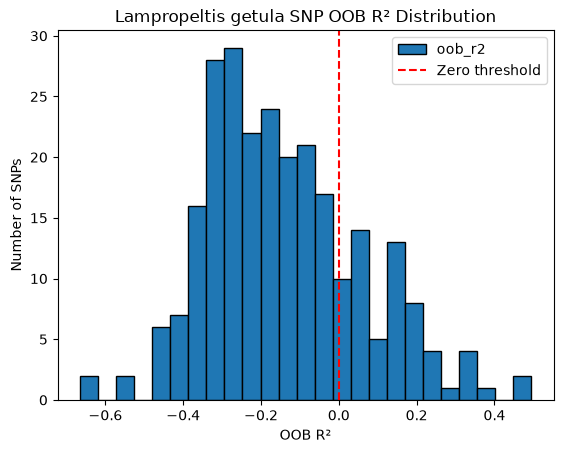

In [16]:
# Store gf.response_scores_ as scores.
# Print evaluated and retained counts and the retained fraction.
# Display scores["reason"].value_counts().
# Plot scores["oob_r2"].dropna() as a histogram, with a reference line at zero.

scores = gf.response_scores_

n_evaluated = len(scores)
n_retained = scores["retained"].sum() if "retained" in scores.columns else (scores["reason"] == "retained").sum()
print(f"Evaluated SNPs: {n_evaluated}")
print(f"Retained SNPs: {n_retained}")
print(f"Retained fraction: {n_retained / n_evaluated:.2%}")

print("\nInclusion reasons:")
print(scores["reason"].value_counts())

ax = scores["oob_r2"].dropna().plot.hist(bins=25, edgecolor="black")
ax.axvline(0, color="red", linestyle="--", label="Zero threshold")
ax.set(title=f"{species_name} SNP OOB R² Distribution", xlabel="OOB R²", ylabel="Number of SNPs")
ax.legend()
plt.show()


**Interpretation:** What does an OOB R² below zero mean? Why does a positive OOB score not establish either adaptation or accurate prediction in a new geographic region?

*Your answer:* An OOB r2 below zero means the model's predictions on held-out samples are worse than simply guessing the average allele dosage across all snakes. A positve OOB r2 only shows a statistical correlation between geography/climate and allele frequencies, not natural selection. And a positive OOB score does not establish accurate prediction in a new geographic region because these models are trained within the specific range of climates and genetic backgrounds of the sampled sites.

## 7. Rank environmental predictors

Plot `gf.importance_` as a horizontal bar chart, as in the lab. Label the axis **Mean allocated OOB R²**. Identify your top three predictors and look up their meanings in the [WorldClim variable definitions](https://www.worldclim.org/data/bioclim.html).

These values average allocated skill over contributing SNPs. They are not percentages of adaptive variation and need not sum to one.


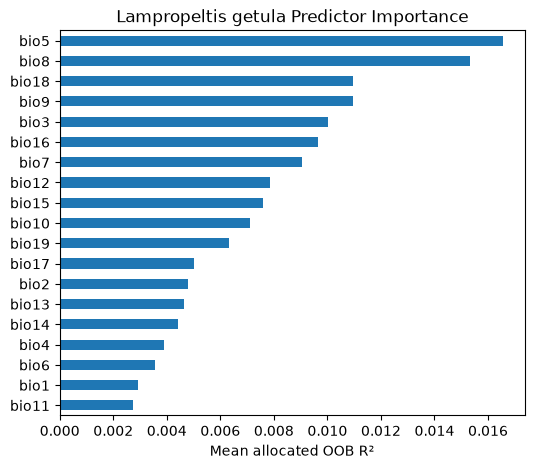

Top 3 predictors:
bio5     0.016544
bio8     0.015341
bio18    0.010974
Name: importance, dtype: float64


In [17]:
# Make a labeled horizontal bar plot of gf.importance_.
# Display the three highest-ranked predictors and their importance values.

ax = gf.importance_.sort_values().plot.barh(
    figsize=(6, 5), 
    xlabel="Mean allocated OOB R²",
    title=f"{species_name} Predictor Importance"
)
plt.show()

print("Top 3 predictors:")
print(gf.importance_.head(3))



**Interpretation:** Name your top three climate variables. Suggest a biological explanation for one association, and one reason that predictor importance does not isolate a causal effect. How could correlation among the 19 climate predictors complicate the ranking?

*Your answer:* Top three are: bio5, bio8, and bio18. bio5 is the max temp of the warmest month which can coorelate to the peak summer heat, meaning that this could influence things like activity levels for metablosim. bio8 is mean temperature of wettest quarter and this could influence kingsnake's diets, allowing the snakes to eat more. and bio18 is the precipitation of the warmest quarter is similar to bio8. 

## 8. Plot cumulative turnover curves

Run the lab's plotting recipe below to show the six leading predictors. Each x axis uses that predictor's environmental values; check the raster units or scaling before assigning physical units. Each endpoint equals the predictor's importance.


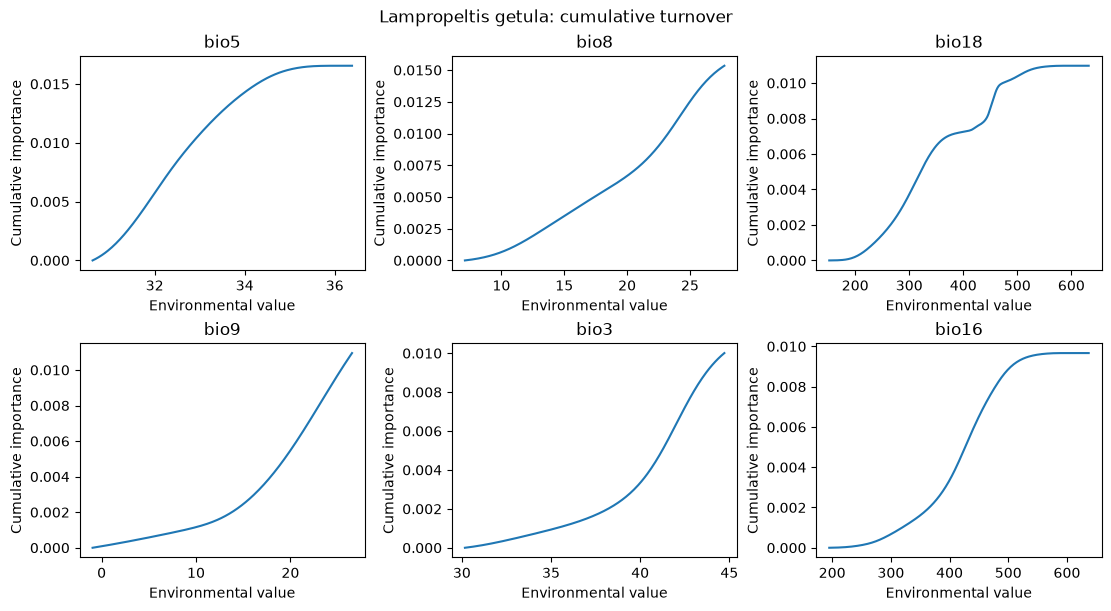

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), layout="constrained")
for ax, name in zip(axes.flat, gf.importance_.head(6).index):
    curve = gf.turnover_[name]
    ax.plot(curve.value, curve.cumulative_importance)
    ax.set(title=name, xlabel="Environmental value", ylabel="Cumulative importance")
fig.suptitle(f"{species_name}: cumulative turnover")
plt.show()
curves_figure = fig


**Interpretation:** Choose one curve and describe the environmental interval where it rises most rapidly, using approximate x-axis values. What does a high but flat section mean? Why can the cumulative curve increase even when some SNP dosages decrease along the gradient?

*Your answer:* Bio5's curve rises most steeply between 31 and 34 where cumulative importance climbs rapdily from near 0 to 0.015 which indicates the sharpest shift in allele frequencies across moderately warm to hot summer max temps. A high, flat plateau means that all major genetic turnover along that environmental gradient has already occured at lower values. Cumulative importance measures the total magnitude of genetic change (variance explained) at each environmental split, not the direction of allele frequency change.

## 9. Transform sampled environments and map a turnover layer

Use `gf.transform(X)` to create `turnover`, then display its first rows and dimensions. This returns one turnover coordinate per environmental predictor for each individual. In pyGF, `predict()` aliases `transform()`; it does not return predicted allele frequencies.

The map call below uses the leading predictor and the same regional bioclim directory. It samples every fourth raster cell in a region buffered 20% around the sites, as in the lab. Missing predictor pixels are masked; values beyond a fitted predictor range are clamped to its curve endpoint.


In [21]:
# Create turnover with gf.transform(X).
# Display turnover.head() and turnover.shape.

turnover = gf.transform(X)
print("Turnover dimensions (individuals, predictors):", turnover.shape)
display(turnover.head())


Turnover dimensions (individuals, predictors): (35, 19)


,bio1,bio2,bio3,bio4,bio5,bio6,bio7,bio8,bio9,bio10,bio11,bio12,bio13,bio14,bio15,bio16,bio17,bio18,bio19
sample,,,,,,,,,,,,,,,,,,,
KU289566,0.002389,0.001387,0.002043,0.001894,0.013356,0.002687,0.001870,0.005398,0.010950,0.006031,0.001947,0.005583,0.001340,0.002703,0.002008,0.002966,0.003597,0.002239,0.005296
MVZ175927,0.001245,0.002100,0.001810,0.002071,0.005569,0.001785,0.002498,0.011704,0.001314,0.003073,0.001286,0.003863,0.000543,0.002629,0.000000,0.001278,0.003401,0.005242,0.003204
MVZ137799,0.002376,0.003873,0.007416,0.001327,0.012938,0.002840,0.001502,0.014192,0.004507,0.004749,0.002131,0.003845,0.000817,0.001788,0.003054,0.001727,0.002648,0.006633,0.003615
OMNH12624,0.001292,0.002419,0.000759,0.002992,0.013408,0.001097,0.006186,0.006668,0.000512,0.004534,0.000960,0.001912,0.001146,0.000396,0.006800,0.001221,0.000905,0.001010,0.000793
OMNH5006,0.001660,0.002495,0.000956,0.002677,0.013924,0.001429,0.005211,0.006848,0.000625,0.004894,0.001234,0.003431,0.001469,0.001117,0.005905,0.002167,0.002096,0.001284,0.001681


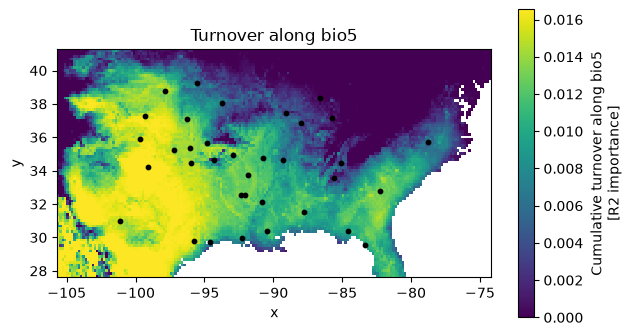

In [22]:
turnover_map = gf.plot_turnover(environment=bioclim_dir, points=sites)


**Interpretation:** Which predictor is mapped? Describe one geographic transition in its transformed values. Why is a high map value not necessarily a place with rapid local turnover? What happens outside the predictor's training range, and why does this limit interpretation?

*Your answer:*

## 10. Make an aggregate spatial PCA biplot

Create `biplot` with `gf.plot_biplot(X, sites, environment=bioclim_dir, n_vectors=3)`. The map and ordination share colors from the first three PCs of the GF-transformed environments. PC1 and PC2 locate points in the biplot; PC1/2/3 supply the color channels.

The PCA uses transformed raster environments without standardizing columns to unit variance, preserving GF importance weights. Labelled arrows are environmental covariance loadings: direction indicates increasing transformed environmental values, and relative length indicates contribution to the displayed PC1/2 pattern.


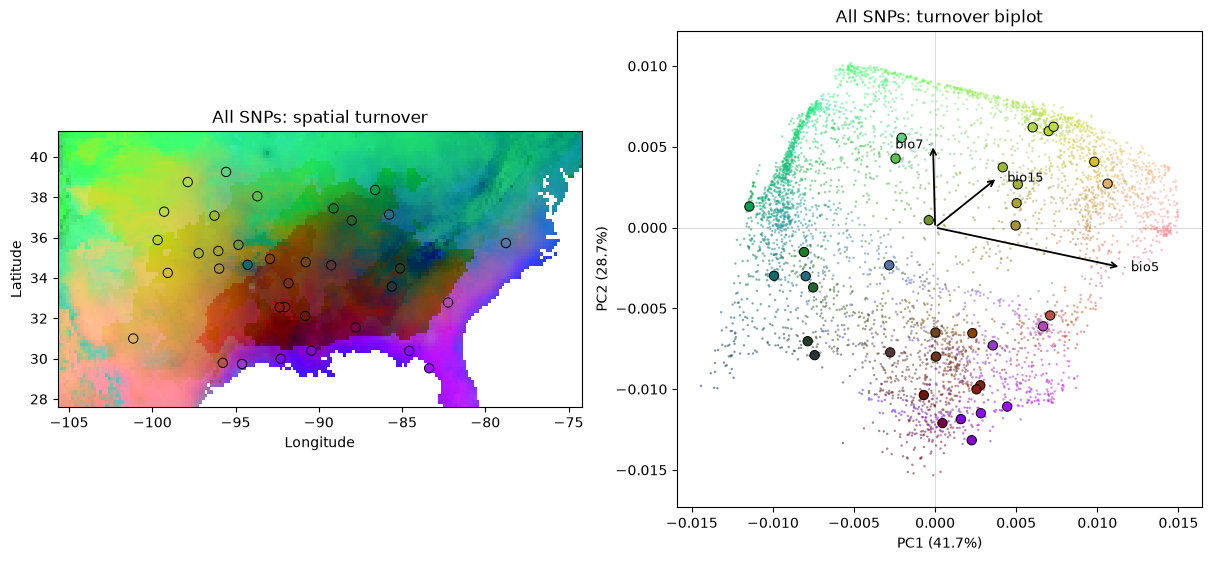

In [23]:
# Create biplot with the call above.
# Display biplot.vectors to inspect the environmental arrows.

biplot = gf.plot_biplot(X, sites, environment="/home/jovyan/shared/bioclim", n_vectors=3)
# gf.plot_biplot() calls the model's ordination pltting function which takes the transformed turnover values across all climate variables and compresses them into three
# principle components (pc1, pc2, and pc3)
# x and sites passes your environmental table (x) and sample locations (sites) so the function can plot the exact snake collection sites as points over the landscape
# and inside the PCA ordination space
# n_vectors=3. draws and labels the top 3 climate arrows on the PCA biplot, the direction and length of each arrow show which climate gradients drive teh strongest patterns
# of genetic variation across the PC1 and Pc2 axes

**Interpretation:** Describe the main geographic color transition and an environmental arrow associated with it. What does similarity in color summarize? Why do neither the colors nor the arrows measure fitness or prove local adaptation?

*Your answer:*

## 11. Compare with a single-SNP biplot

Select the highest-OOB-R² SNP among contributing responses using the provided code. Create `snp_biplot` with the same call as before, adding `response=snp`. Use **`environment=bioclim_dir` in both biplot calls**, rather than an upstream-relative `../envs` path.

Each response has its own PCA basis and color calibration. Compare geographic organization and arrows; matching colors across separate plots have no shared genetic meaning. Selecting the best-scoring SNP is an illustration, not independent validation or discovery of an adaptive locus.


Selected SNP: RAD_13936:1:G:A
n_observed            31
oob_r2          0.494156
oob_coverage         1.0
retained            True
reason          retained
Name: RAD_13936:1:G:A, dtype: object


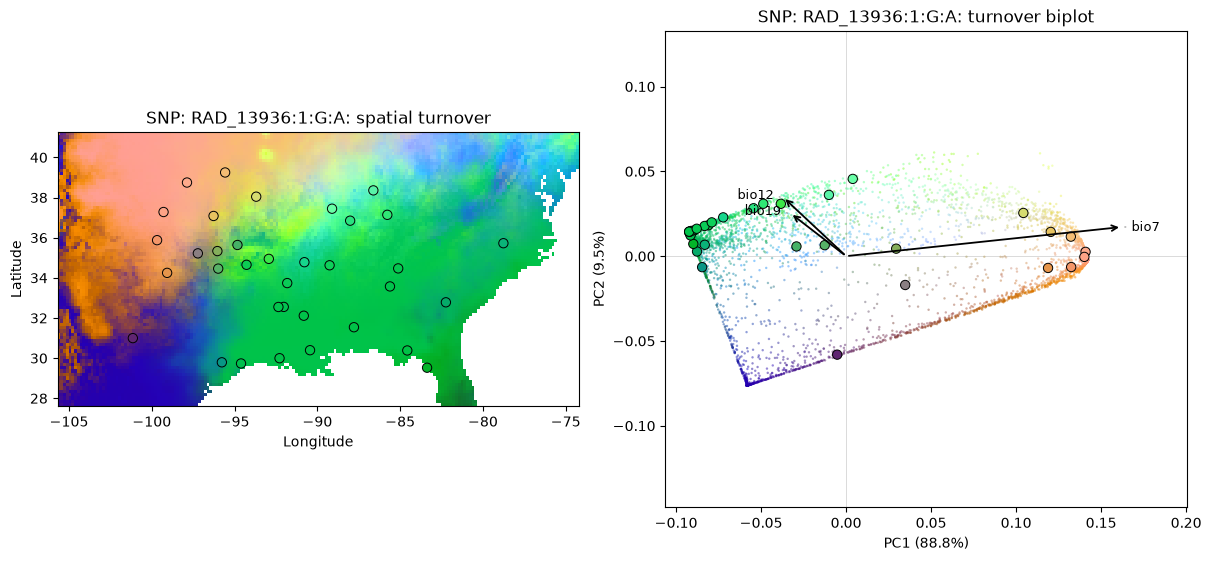

In [24]:
contributing_scores = gf.response_scores_.loc[gf.response_scores_["retained"]]
snp = contributing_scores["oob_r2"].idxmax()
print("Selected SNP:", snp)
print(contributing_scores.loc[snp])

# Create snp_biplot using gf.plot_biplot(), environment=bioclim_dir,
# response=snp, and n_vectors=3.

snp = gf.response_scores_.oob_r2.idxmax()
# gf.response_scores_.oob_r2 grabs the out of bag r2 score colummn for every SNP in the model
# .idmax() finds the row with the highest r2 score and returns its index name (the specific ID of that top SNP)
# snp. saves the winning SNP ID into a variable named snp
snp_biplot = gf.plot_biplot(X, sites, environment="/home/jovyan/shared/bioclim", response=snp, n_vectors=3)

**Interpretation:** How does this SNP's geographic pattern differ from the aggregate pattern? Can you interpret a red region in both plots as the same genetic composition? Explain.

*Your answer:*

## 12. Export your results

The export recipe below follows the lab. It saves outputs under `Assignment09_outputs/<your file stem>/`, keeping runs for different species separate. The GeoTIFF contains one named band per environmental predictor, not per SNP.

Run the cell after completing the earlier steps. Keep the sample IDs in exported tables and preserve the raster's CRS and NoData mask. The small summary records the species, data paths, filtering choices, and model settings used in this analysis.


In [25]:
gf.response_scores_.to_csv(output_dir / "snp_oob_scores.csv")
gf.importance_.to_csv(output_dir / "predictor_importance.csv")
turnover.to_csv(output_dir / "sample_turnover.csv")
sites[["longitude", "latitude"]].to_csv(output_dir / "sample_coordinates.csv")
pd.concat(gf.turnover_, names=["predictor", "bin"]).to_csv(output_dir / "turnover_curves.csv")

summary = pd.DataFrame([{
    "species": species_name,
    "file_stem": target_species,
    "vcf": str(vcf_path),
    "coordinates": str(coords_path),
    "bioclim_directory": str(bioclim_dir),
    "n_individuals": len(X),
    "n_predictors": X.shape[1],
    "n_snps": y.shape[1],
    "n_contributing": int(gf.response_scores_["retained"].sum()),
    "min_call_rate": 0.8,
    "min_maf": 0.05,
    "one_per_contig": True,
    "max_variants": 256,
    "n_estimators": 100,
    "max_level": 2,
    "random_state": 42,
}])
summary.to_csv(output_dir / "analysis_summary.csv", index=False)

bands = turnover_map.turnover.to_array("band").rio.write_nodata(np.nan)
bands.attrs["long_name"] = tuple(X.columns)
bands.rio.to_raster(output_dir / "genomic_turnover.tif", compress="deflate", dtype="float32")

curves_figure.savefig(output_dir / "turnover_curves.png", dpi=150, bbox_inches="tight")
turnover_map.figure.savefig(output_dir / "turnover_map.png", dpi=150, bbox_inches="tight")
biplot.figure.savefig(output_dir / "turnover_biplot.png", dpi=150, bbox_inches="tight")
snp_biplot.figure.savefig(output_dir / "snp_biplot.png", dpi=150, bbox_inches="tight")

print("Saved results to:", output_dir.resolve())
summary


Saved results to: /home/jovyan/BIO597-SpatialBiodiversity/docs/assignments/Assignment09_outputs/Lgetula


,species,file_stem,vcf,coordinates,bioclim_directory,n_individuals,n_predictors,n_snps,n_contributing,min_call_rate,min_maf,one_per_contig,max_variants,n_estimators,max_level,random_state
0,Lampropeltis getula,Lgetula,/home/jovyan/shared/EasternSnakeGenetics/Lgetu...,/home/jovyan/shared/EasternSnakeGenetics/Lgetu...,/home/jovyan/shared/bioclim,35,19,256,61,0.8,0.05,True,256,100,2,42


## Final reflection

Answer each question in two or three sentences, referring to your figures or diagnostic results.

1. How does this genotype-based analysis differ from the species presence/background SDMs in Labs07–08? Why is a turnover coordinate different from a suitability score or allele frequency?
2. Which predictor and environmental interval showed a clear turnover pattern for your species? What evidence supports your description, and what sampling or modeling choice could change it?
3. Describe one alternative to local adaptation that could produce a genetic–environmental association. What additional data or analysis would help distinguish the explanations?
4. What would you withhold to test prediction in a new region? Explain why OOB evaluation alone does not answer that question.

*Your answers:* Unlike presence/background SMDs in labs 7 and 8, the gradient forest anaysis models intraspecific genetic variation (SNP allele dosages) to map where allele frequencies shift across environmental gradients within the species range. Bio5 ranked highest in predictor importance and shows its sharpest turnover between 31 and 34 on the cumulative turnover curve before plateuing above 35, this pattern is supported by the steep upward slope of the bio5 curve and the rapdi color transition across the 

## Submit your work

Restart the kernel and run the notebook from top to bottom after completing the code prompts. Check that your figures appear, written answers are filled in, diagnostic counts are reported, and all exports exist. Commit and push this notebook and your species' output folder to your class GitHub repository. The original VCF and climate rasters remain in shared storage and should not be included in your submission.

Run these Git commands **from the repository root**, replacing `YOUR_SPECIES` with your chosen file stem:

```bash
git add docs/assignments/Assignment-09-GradientForest.ipynb docs/assignments/Assignment09_outputs/YOUR_SPECIES/
git commit -m "Complete Gradient Forest assignment"
git push
```

## References

- [Lab09: Gradient Forest](../labs/Lab09-GradientForest.ipynb)
- [Lecture09: Gradient Forest and Genomic Turnover](../lectures/Lecture09-GradientForest.html)
- [pyGF implementation and interpretation notes](https://github.com/isaacovercast/pygf)
- [Ellis, Smith & Pitcher (2012): the original Gradient Forest method](https://doi.org/10.1890/11-0252.1)
- [WorldClim bioclimatic variable definitions](https://www.worldclim.org/data/bioclim.html)
